In [1]:
library(fdrtool)
library(dplyr)
library(ggplot2)
library(ggrepel)


Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union




In [2]:
df = read.csv('../intmd/sc-THP1_to_tradeSeq/asso_df.thp1.1trajectory.nknots4.expanded.csv')
df = df[!is.na(df$waldStat_1), ]

In [5]:
p_raw <- df$pvalue_1
min_pos <- min(p_raw[p_raw > 0], na.rm=TRUE)
p <- if (is.finite(min_pos)) pmax(p_raw, min_pos/10) else pmax(p_raw, 1e-300)
p <- pmin(p, 1 - 1e-16)

ft <- fdrtool(p, statistic="pvalue", plot=FALSE, verbose=FALSE)
df$lfdr <- ft$lfdr

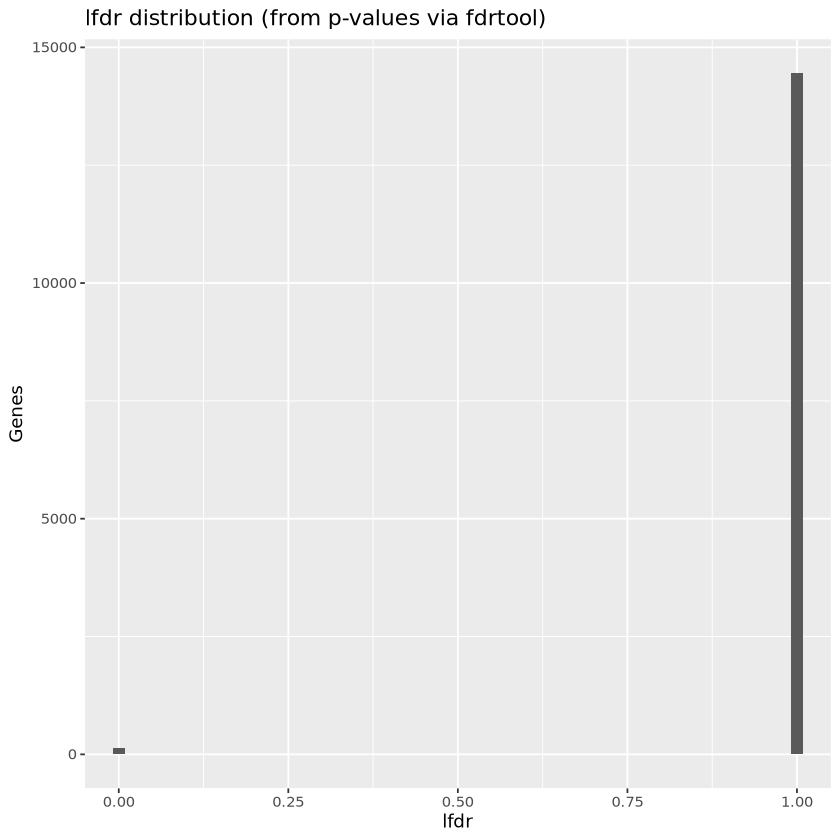

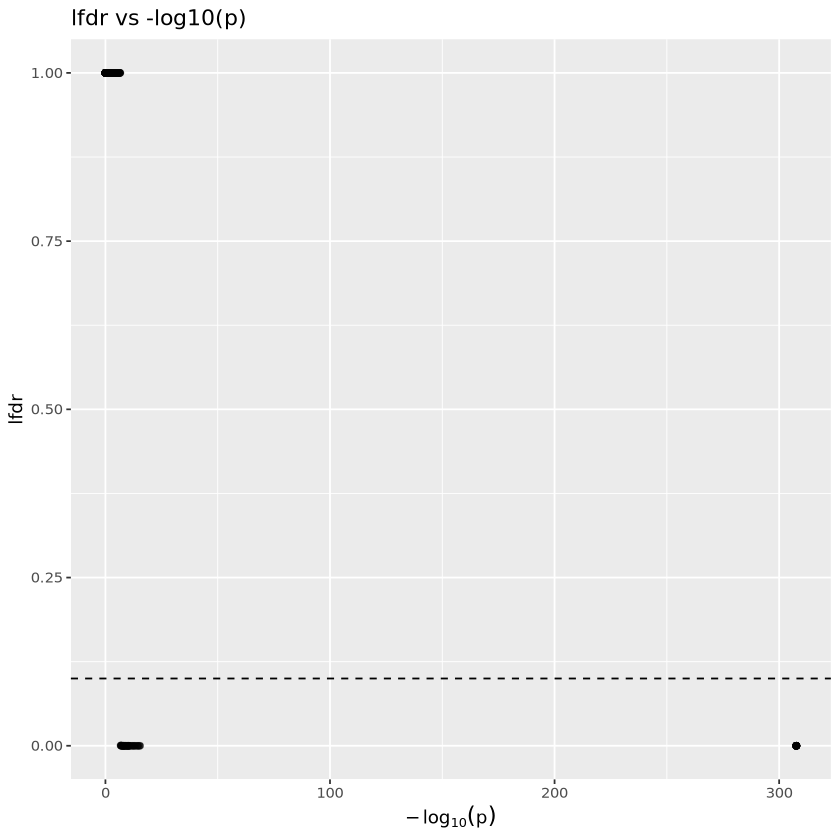

In [6]:
library(ggplot2)
library(dplyr)
library(ggrepel)

df$mlog10p <- -log10(pmax(df$pvalue_1, .Machine$double.xmin))

ggplot(df, aes(lfdr)) +
  geom_histogram(bins=60) +
  coord_cartesian(xlim=c(0,1)) +
  labs(x="lfdr", y="Genes", title="lfdr distribution (from p-values via fdrtool)")

ggplot(df, aes(mlog10p, lfdr)) +
  geom_point(alpha=0.25) +
  geom_hline(yintercept=0.1, linetype=2) +
  labs(x=expression(-log[10](p)), y="lfdr", title="lfdr vs -log10(p)")

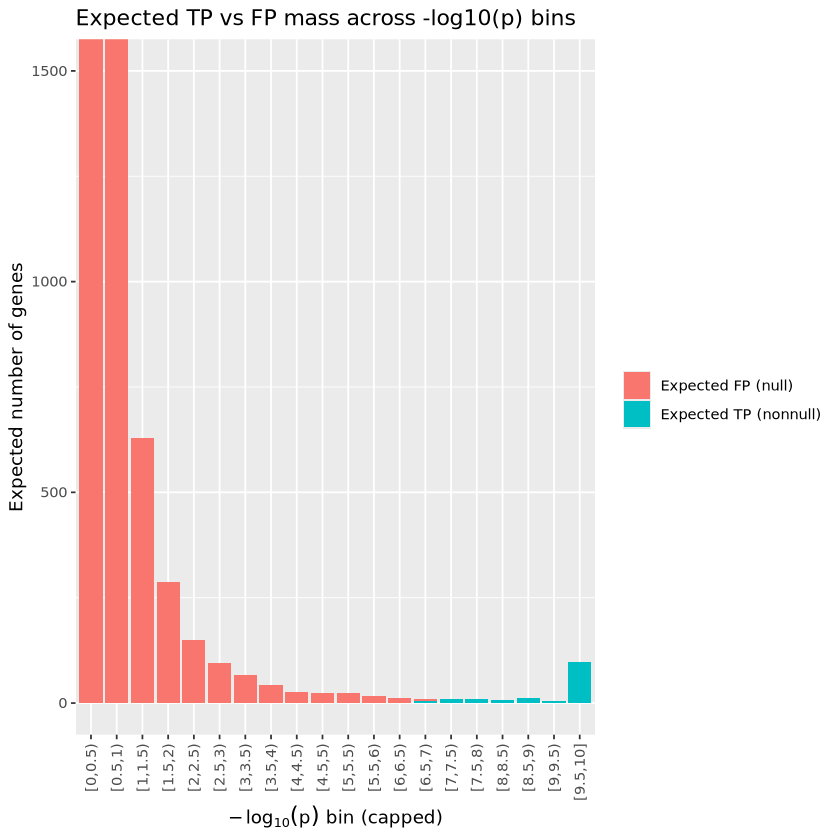

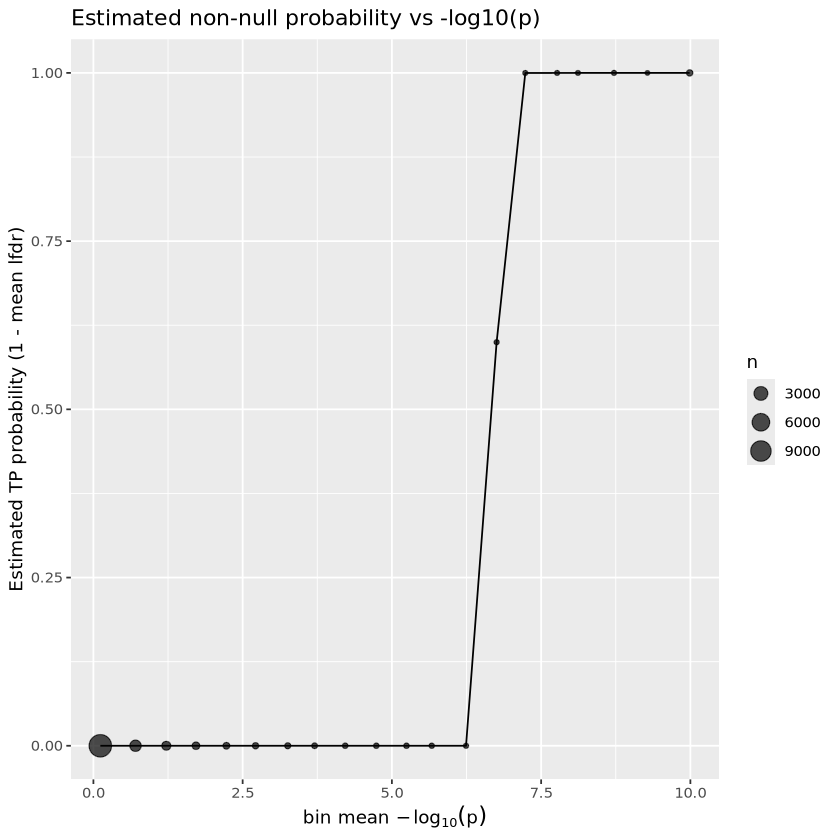

In [7]:
library(dplyr)
library(tidyr)
library(ggplot2)

# assumes you already have df$lfdr and df$pvalue_1
df2 <- df %>%
  mutate(
    p_plot  = pmax(pvalue_1, .Machine$double.xmin),
    score   = -log10(p_plot)
  ) %>%
  filter(is.finite(score), is.finite(lfdr))

# pick bins (adjust if you like)
# Here: 0 to max with 0.5 step, capped at 30 for readability (change cap as needed)
cap <- 10
binw <- 0.5

df_binned <- df2 %>%
  mutate(score_cap = pmin(score, cap),
         bin = cut(score_cap,
                   breaks = seq(0, cap, by = binw),
                   include.lowest = TRUE, right = FALSE)) %>%
  group_by(bin) %>%
  summarise(
    n = n(),
    exp_FP = sum(lfdr),
    exp_TP = sum(1 - lfdr),
    mean_score = mean(score_cap),
    .groups = "drop"
  ) %>%
  pivot_longer(c(exp_FP, exp_TP), names_to = "class", values_to = "exp_count") %>%
  mutate(class = recode(class, exp_FP = "Expected FP (null)", exp_TP = "Expected TP (nonnull)"))

ggplot(df_binned, aes(x = bin, y = exp_count, fill = class)) +
  geom_col() +
  coord_cartesian(ylim = c(0, 1500)) +   # <- add this
  labs(x = expression(-log[10](p)~"bin (capped)"),
       y = "Expected number of genes",
       title = "Expected TP vs FP mass across -log10(p) bins",
       fill = "") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1))

df_frac <- df2 %>%
  mutate(score_cap = pmin(score, cap),
         bin = cut(score_cap, breaks = seq(0, cap, by = binw),
                   include.lowest = TRUE, right = FALSE)) %>%
  group_by(bin) %>%
  summarise(
    mean_score = mean(score_cap),
    tp_frac = mean(1 - lfdr),
    n = n(),
    .groups = "drop"
  )

ggplot(df_frac, aes(x = mean_score, y = tp_frac)) +
  geom_point(aes(size = n), alpha = 0.7) +
  geom_line() +
  labs(x = expression("bin mean " * -log[10](p)),
       y = "Estimated TP probability (1 - mean lfdr)",
       title = "Estimated non-null probability vs -log10(p)") +
  ylim(0, 1)

We define a joint score for each TF-gene pair as $S_{t,g} = r_{t}(1-lfdr_{g})$, where $r_t$ is the stimulus-conditioned TF prior weight and ($1-lfdr_g$) is the estimated probability that gene $g$ is dynamically regulated. Here, we treat $r_t$ as an approximation of the TF's responsibility, i.e. ($P(t \leftarrow g | g$ is dynamic). Importantly, $r_t$ does not inherently leverage TF-gene-specific evidence and instead reflects an epistemic uncertainty regarding the set of TFs whose activities are ultimately perturbed by a stimulus and are therefore expected to regulate the observed gene dynamics. In principle, chromatin accessibility evidence can be leveraged as soft prior to better estimate the responsibility $r_{tg}$, but this requires careful calibration.

In [16]:
write.csv(df, '../intmd/sc-THP1_to_tradeSeq/asso_df.1trajectory.lfdr.csv', row.names = TRUE)